# EDA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency, mannwhitneyu
import numpy as np

## Обзор всех таблиц

Загрузка основного датасета.

In [2]:
application = pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/application_train.csv")

Датасет имеет $122$ колонки, включая целевую переменную $TARGET$, которая означает есть ли у клиента проблемы с погашением кредита. Всего в трейновом датасете $307 511$ записей.

Типы данных, встречающихся в $df$.

In [3]:
application.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

Оценим, насколько сбалансированы классы:

In [4]:
application['TARGET'].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

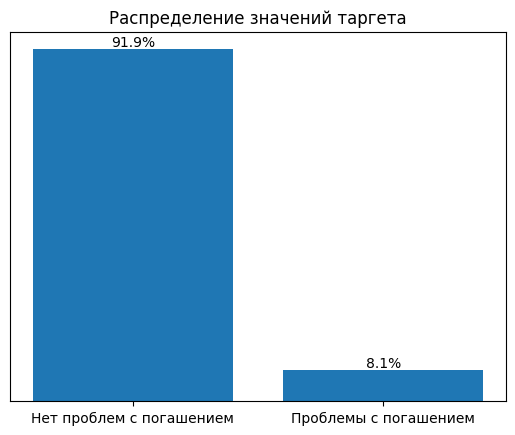

In [5]:
bars = plt.bar([0, 1], application['TARGET'].value_counts(normalize=True).sort_index() * 100)
plt.title("Распределение значений таргета")
plt.bar_label(bars, fmt="%.1f%%")
plt.xticks([0, 1], ["Нет проблем с погашением", "Проблемы с погашением"])
plt.yticks([])
plt.show()

Наблюдается дисбаланс классов. 

Также посмотрим на дополнительные таблицы.

In [6]:
bureau = pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/bureau.csv")
installments = pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/installments_payments.csv")
previous = pd.read_csv(
    "/kaggle/input/competitions/home-credit-default-risk/previous_application.csv"
)
pos = pd.read_csv(
    "/kaggle/input/competitions/home-credit-default-risk/POS_CASH_balance.csv"
)
cc = pd.read_csv(
    "/kaggle/input/competitions/home-credit-default-risk/credit_card_balance.csv"
)
bb = pd.read_csv("/kaggle/input/competitions/home-credit-default-risk/bureau_balance.csv")

Информация о дополнительных таблицах:

* bureau — информация о предыдущих и действующих кредитах клиентов в других финансовых организациях.

* bureau_balance — помесячная история состояния кредитов из bureau.

* previous_application — информация о предыдущих кредитных заявках клиентов в Home Credit.

* installments_payments — история платежей по ранее выданным кредитам.

* POS_CASH_balance — помесячная информация о потребительских кредитах и кредитах на покупку товаров.

* credit_card_balance — помесячная информация о кредитных картах клиентов.

Дополнительные источники позволяют получить характеристики кредитной истории, платёжной дисциплины и долговой нагрузки заёмщиков.

In [7]:
tables = {
    "bureau": bureau,
    "bureau_balance": bb,
    "previous_application": previous,
    "installments_payments": installments,
    "POS_CASH_balance": pos,
    "credit_card_balance": cc
}

Краткая информация о дополнительных таблицах:

In [8]:
for name, table in tables.items():
    print(f"\n{name}")
    print(f"Размер: {table.shape}")

    if "SK_ID_CURR" in table.columns:
        print(f"Уникальных клиентов: {table['SK_ID_CURR'].nunique()}")

    if "SK_ID_PREV" in table.columns:
        print(f"Уникальных предыдущих заявок: {table['SK_ID_PREV'].nunique()}")

    if "SK_ID_BUREAU" in table.columns:
        print(f"Уникальных кредитов бюро: {table['SK_ID_BUREAU'].nunique()}")


bureau
Размер: (1716428, 17)
Уникальных клиентов: 305811
Уникальных кредитов бюро: 1716428

bureau_balance
Размер: (27299925, 3)
Уникальных кредитов бюро: 817395

previous_application
Размер: (1670214, 37)
Уникальных клиентов: 338857
Уникальных предыдущих заявок: 1670214

installments_payments
Размер: (13605401, 8)
Уникальных клиентов: 339587
Уникальных предыдущих заявок: 997752

POS_CASH_balance
Размер: (10001358, 8)
Уникальных клиентов: 337252
Уникальных предыдущих заявок: 936325

credit_card_balance
Размер: (3840312, 23)
Уникальных клиентов: 103558
Уникальных предыдущих заявок: 104307


Дополнительные таблицы содержат историческую информацию о предыдущих кредитах, заявках и платежах клиентов.

Большинство таблиц имеют связь «один ко многим» с основной таблицей application_train: одному клиенту (SK_ID_CURR) может соответствовать несколько записей.

Таблица bureau_balance связана с bureau через SK_ID_BUREAU и содержит помесячную историю кредитов.

Для объединения дополнительных источников с основной таблицей потребуется агрегировать информацию до уровня одного клиента.

Посмотрим на статистики количества записей на каждого клиента в каждой таблице:

In [9]:
for name, table in tables.items():
    if "SK_ID_CURR" in table.columns:
        print(f"\n{name}")
        display(table.groupby("SK_ID_CURR").size().describe().loc[["mean", "50%", "max"]])


bureau


mean      5.612709
50%       4.000000
max     116.000000
dtype: float64


previous_application


mean     4.928964
50%      4.000000
max     77.000000
dtype: float64


installments_payments


mean     40.064552
50%      25.000000
max     372.000000
dtype: float64


POS_CASH_balance


mean     29.655445
50%      22.000000
max     295.000000
dtype: float64


credit_card_balance


mean     37.083683
50%      22.000000
max     192.000000
dtype: float64

С bureus balance немного иначе: посмотрим на количество записей на каждый кредит.

In [10]:
bb.groupby("SK_ID_BUREAU").size().describe().loc[["mean", "50%", "max"]]

mean    33.398693
50%     26.000000
max     97.000000
dtype: float64

Количество исторических записей существенно различается между клиентами.

Например, в bureau на одного клиента приходится в среднем 5.61 кредита, а в installments_payments — 40.06 записи о платежах.

Это позволяет создавать агрегированные признаки, характеризующие кредитную активность и платёжную дисциплину клиентов: количество предыдущих кредитов, общую задолженность, частоту просрочек и другие показатели.

Подробное исследование этих признаков и их агрегация будут выполнены в разделе Feature Engineering.

# Анализ основных признаков

Разделим датасет на обучающую и отложенную выборки, анализ будем проводить только на train части.

In [11]:
train_ids, test_ids = train_test_split(
    application["SK_ID_CURR"],
    test_size=0.2,
    random_state=42,
    stratify=application["TARGET"]
)
train_ids.to_csv("train_ids.csv")
test_ids.to_csv("test_ids.csv")

In [12]:
df_train = application[application["SK_ID_CURR"].isin(train_ids)].copy()

Посмотрим на то, какой процент клиентов имеет записи в каждой из таблиц.

In [13]:
for name, table in tables.items():
    if "SK_ID_CURR" in table.columns:
        share = df_train["SK_ID_CURR"].isin(table["SK_ID_CURR"]).mean() * 100
        print(f"{name}: {share:.2f}%")
bureau_ids = bureau.loc[
    bureau["SK_ID_BUREAU"].isin(bb["SK_ID_BUREAU"]),
    "SK_ID_CURR"
]

share = df_train["SK_ID_CURR"].isin(bureau_ids).mean() * 100
print(f"bureau_balance: {share:.2f}%")

bureau: 85.67%
previous_application: 94.64%
installments_payments: 94.84%
POS_CASH_balance: 94.13%
credit_card_balance: 28.33%
bureau_balance: 29.94%


## Гипотезы

В некоторых категориях содержится достаточно много признаков и некоторые из них достаточно похожи.

Для того, чтобы не перебирать все признаки, можно сделать несколько предположений о данных и проверить их.

1. Более высокий доход связан с меньшей вероятностью дефолта.
2. Меньшая сумма кредита связана с меньшей вероятностью дефолта.
3. Более старшие клиенты реже допускают дефолт.
4. Проживание не по месту регистрации связано с повышенным риском дефолта.
5. Внешние оценки EXT_SOURCE связаны с вероятностью дефолта.
6. Характеристики зданий сильно коррелируют между собой.

Начнем проверять гипотезы. Сначала поглядим на распределение доходов клиентов.

## Доходы

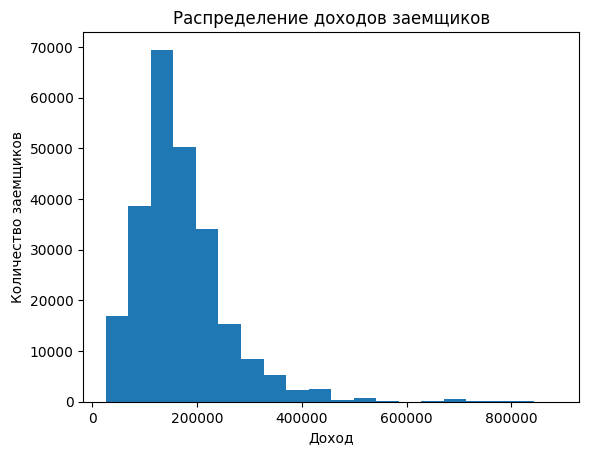

In [14]:
plt.hist(
    df_train.loc[
        df_train["AMT_INCOME_TOTAL"] < df_train["AMT_INCOME_TOTAL"].quantile(0.999),
        "AMT_INCOME_TOTAL"
    ],
    bins=20
)
plt.xlabel("Доход")
plt.ylabel("Количество заемщиков")
plt.title("Распределение доходов заемщиков")
plt.show()

Есть большие значения. Но сложно сказать, что это ошибки в данных. Это действительно могут быть люди с очень высоким доходом. Форма распределения достаточно типичная для доходов - она скошенная, большая часть клиентов имеет одинаковый доход и дальше график убывает.

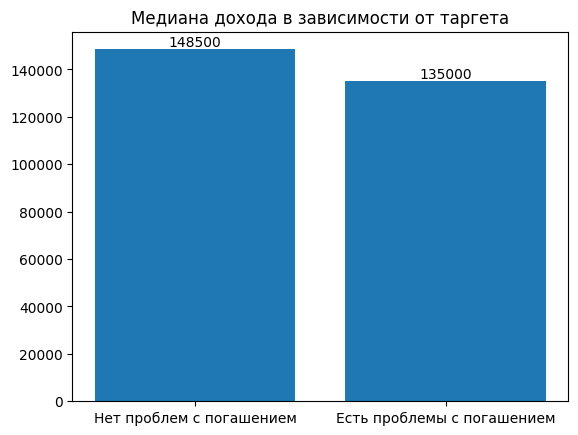

In [15]:
bars = plt.bar([0, 1], df_train.groupby(by="TARGET")["AMT_INCOME_TOTAL"].median())
plt.title("Медиана дохода в зависимости от таргета")
plt.xticks([0, 1], ["Нет проблем с погашением", "Есть проблемы с погашением"])
plt.bar_label(bars)
plt.show()

In [16]:
from scipy.stats import mannwhitneyu

stat, p_value = mannwhitneyu(df_train.loc[df_train["TARGET"] == 0, "AMT_INCOME_TOTAL"],
                            df_train.loc[df_train["TARGET"] == 1, "AMT_INCOME_TOTAL"],
                            alternative="greater")
print(f"P_value: {p_value}")

P_value: 4.1300116737659913e-22


In [17]:
effect_size = stat / (len(df_train[df_train["TARGET"] == 0]) * len(df_train[df_train["TARGET"] == 1]))
print(f"Размер эффекта: {effect_size}")

Размер эффекта: 0.5204541276973197


**Вывод**

Действительно, медиана доходов заемщиков без проблем с погашением выше. Это подтверждает тест Манна-Уитни. Однако размер эффекта мал. То есть распределения доходов при таргете 0 и 1 сильно перекрываются. Так что этот признак обладает небольшой разделяющей способностью, но, естественно, бесполезным его назвать нельзя.

## Сумма кредита

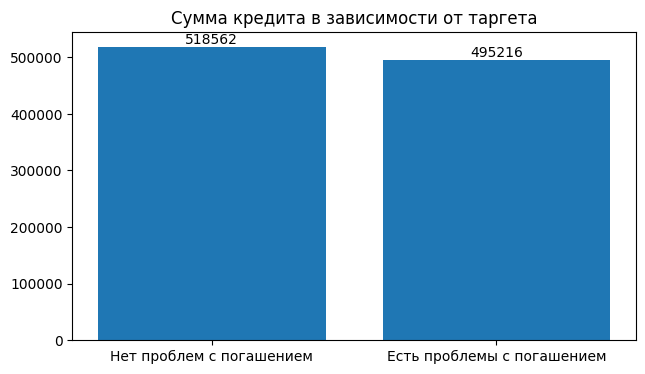

In [18]:
plt.figure(figsize=(16, 4))
plt.subplot(1, 2, 1)
bars = plt.bar([0, 1], df_train.groupby(by="TARGET")["AMT_CREDIT"].median())
plt.title("Сумма кредита в зависимости от таргета")
plt.xticks([0, 1], ["Нет проблем с погашением", "Есть проблемы с погашением"])
plt.bar_label(bars)
plt.show()

Как ни странно, медиана суммы кредита заемщиков без проблем с погашением оказалась выше.

## Возраст и регистрация

In [19]:
df_train["age"] = df_train["DAYS_BIRTH"]/(-365)

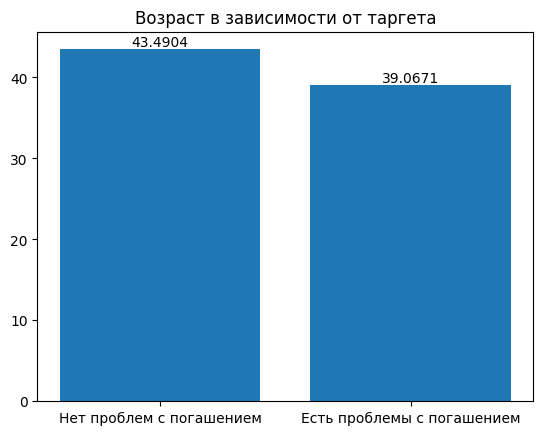

In [20]:
bars = plt.bar([0, 1], df_train.groupby(by="TARGET")["age"].median())
plt.title("Возраст в зависимости от таргета")
plt.xticks([0, 1], ["Нет проблем с погашением", "Есть проблемы с погашением"])
plt.bar_label(bars)
plt.show()

На графике видно, что те, кто младше чаще имеют проблемы с погашением. Проверим наблюдения с помощью теста Манна-Уитни.

In [21]:
stat, p_value = mannwhitneyu(df_train.loc[df_train["TARGET"] == 0, "age"],
                            df_train.loc[df_train["TARGET"] == 1, "age"],
                            alternative="greater")
print(f"P_value: {p_value}")

P_value: 0.0


In [22]:
effect_size = stat / (len(df_train[df_train["TARGET"] == 0]) * len(df_train[df_train["TARGET"] == 1]))
print(f"Размер эффекта: {effect_size}")

Размер эффекта: 0.5843213514375288


На этот раз размер эффекта несколько больше. Те, кто младше чаще имеют проблемы с погашением.

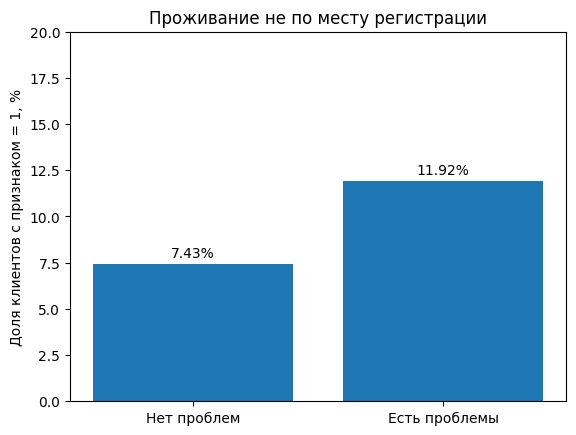

In [23]:
values = df_train.groupby("TARGET")["REG_CITY_NOT_LIVE_CITY"].mean() * 100
bars = plt.bar([0, 1], values)
plt.title("Проживание не по месту регистрации")
plt.xticks([0, 1], ["Нет проблем", "Есть проблемы"])
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylim(0, 20)
plt.ylabel("Доля клиентов с признаком = 1, %")
plt.show()

In [24]:
table = pd.crosstab(df_train['REG_CITY_NOT_LIVE_CITY'], df_train['TARGET'])
chi2, p_value, dof, expected = chi2_contingency(table)
phi = np.sqrt(chi2 / table.to_numpy().sum())
print(f'Phi: {phi:.4f}')
print(f'p-value: {p_value:.5f}')

Phi: 0.0456
p-value: 0.00000


Среди клиентов без дефолта доля проживающих не по месту регистрации составляет 7,43%, тогда как среди клиентов с дефолтом — 11,92%. Критерий хи-квадрат выявил статистически значимую связь, но коэффициент Phi показывает, что её сила очень мала.

## Внешние оценки

Внешние оценки могут оказаться важным признаком для определения проблемности клиента.

In [25]:
external_scores = [
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

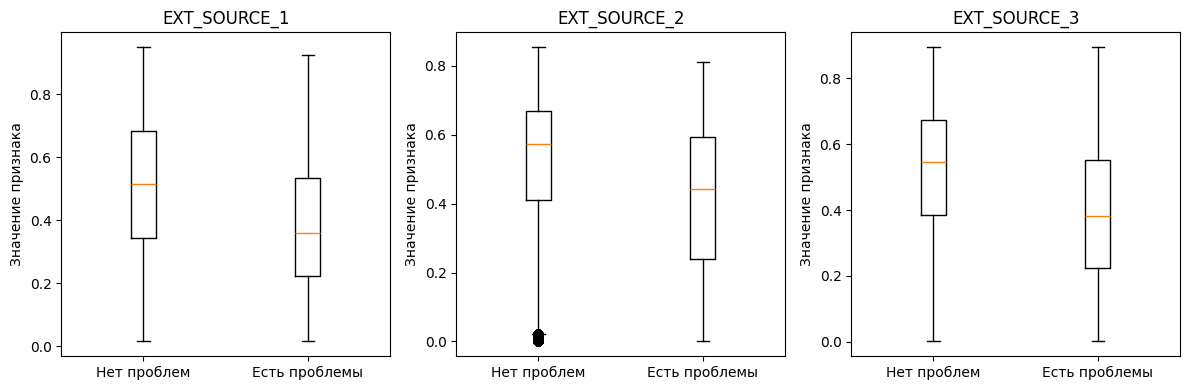

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for col, ax in zip(external_scores, axes.flatten()):
    boxes = ax.boxplot([df_train.loc[df_train["TARGET"] == 0, col].dropna(), 
                        df_train.loc[df_train["TARGET"] == 1, col].dropna()], 
                       tick_labels=["Нет проблем", "Есть проблемы"])
    ax.set_title(col)
    ax.set_ylabel("Значение признака")

plt.tight_layout()
plt.show()

Видно, что значения внешних оценок действительно меньше, если у заемщика есть проблемы с погашением.

## Характеристики здания

Среди этих признаков много пропущенных значений:

In [27]:
building = [
    'APARTMENTS_AVG',
    'BASEMENTAREA_AVG',
    'YEARS_BEGINEXPLUATATION_AVG',
    'YEARS_BUILD_AVG',
    'COMMONAREA_AVG',
    'ELEVATORS_AVG',
    'ENTRANCES_AVG',
    'FLOORSMAX_AVG',
    'FLOORSMIN_AVG',
    'LANDAREA_AVG',
    'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG',
    'NONLIVINGAPARTMENTS_AVG',
    'NONLIVINGAREA_AVG',

    'APARTMENTS_MODE',
    'BASEMENTAREA_MODE',
    'YEARS_BEGINEXPLUATATION_MODE',
    'YEARS_BUILD_MODE',
    'COMMONAREA_MODE',
    'ELEVATORS_MODE',
    'ENTRANCES_MODE',
    'FLOORSMAX_MODE',
    'FLOORSMIN_MODE',
    'LANDAREA_MODE',
    'LIVINGAPARTMENTS_MODE',
    'LIVINGAREA_MODE',
    'NONLIVINGAPARTMENTS_MODE',
    'NONLIVINGAREA_MODE',

    'APARTMENTS_MEDI',
    'BASEMENTAREA_MEDI',
    'YEARS_BEGINEXPLUATATION_MEDI',
    'YEARS_BUILD_MEDI',
    'COMMONAREA_MEDI',
    'ELEVATORS_MEDI',
    'ENTRANCES_MEDI',
    'FLOORSMAX_MEDI',
    'FLOORSMIN_MEDI',
    'LANDAREA_MEDI',
    'LIVINGAPARTMENTS_MEDI',
    'LIVINGAREA_MEDI',
    'NONLIVINGAPARTMENTS_MEDI',
    'NONLIVINGAREA_MEDI',

    'FONDKAPREMONT_MODE',
    'HOUSETYPE_MODE',
    'TOTALAREA_MODE',
    'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE'
]

In [28]:
df_train[building].isna().sum()

APARTMENTS_AVG                  124732
BASEMENTAREA_AVG                143829
YEARS_BEGINEXPLUATATION_AVG     119949
YEARS_BUILD_AVG                 163543
COMMONAREA_AVG                  171811
ELEVATORS_AVG                   131017
ENTRANCES_AVG                   123775
FLOORSMAX_AVG                   122297
FLOORSMIN_AVG                   166921
LANDAREA_AVG                    145985
LIVINGAPARTMENTS_AVG            168119
LIVINGAREA_AVG                  123462
NONLIVINGAPARTMENTS_AVG         170729
NONLIVINGAREA_AVG               135624
APARTMENTS_MODE                 124732
BASEMENTAREA_MODE               143829
YEARS_BEGINEXPLUATATION_MODE    119949
YEARS_BUILD_MODE                163543
COMMONAREA_MODE                 171811
ELEVATORS_MODE                  131017
ENTRANCES_MODE                  123775
FLOORSMAX_MODE                  122297
FLOORSMIN_MODE                  166921
LANDAREA_MODE                   145985
LIVINGAPARTMENTS_MODE           168119
LIVINGAREA_MODE          

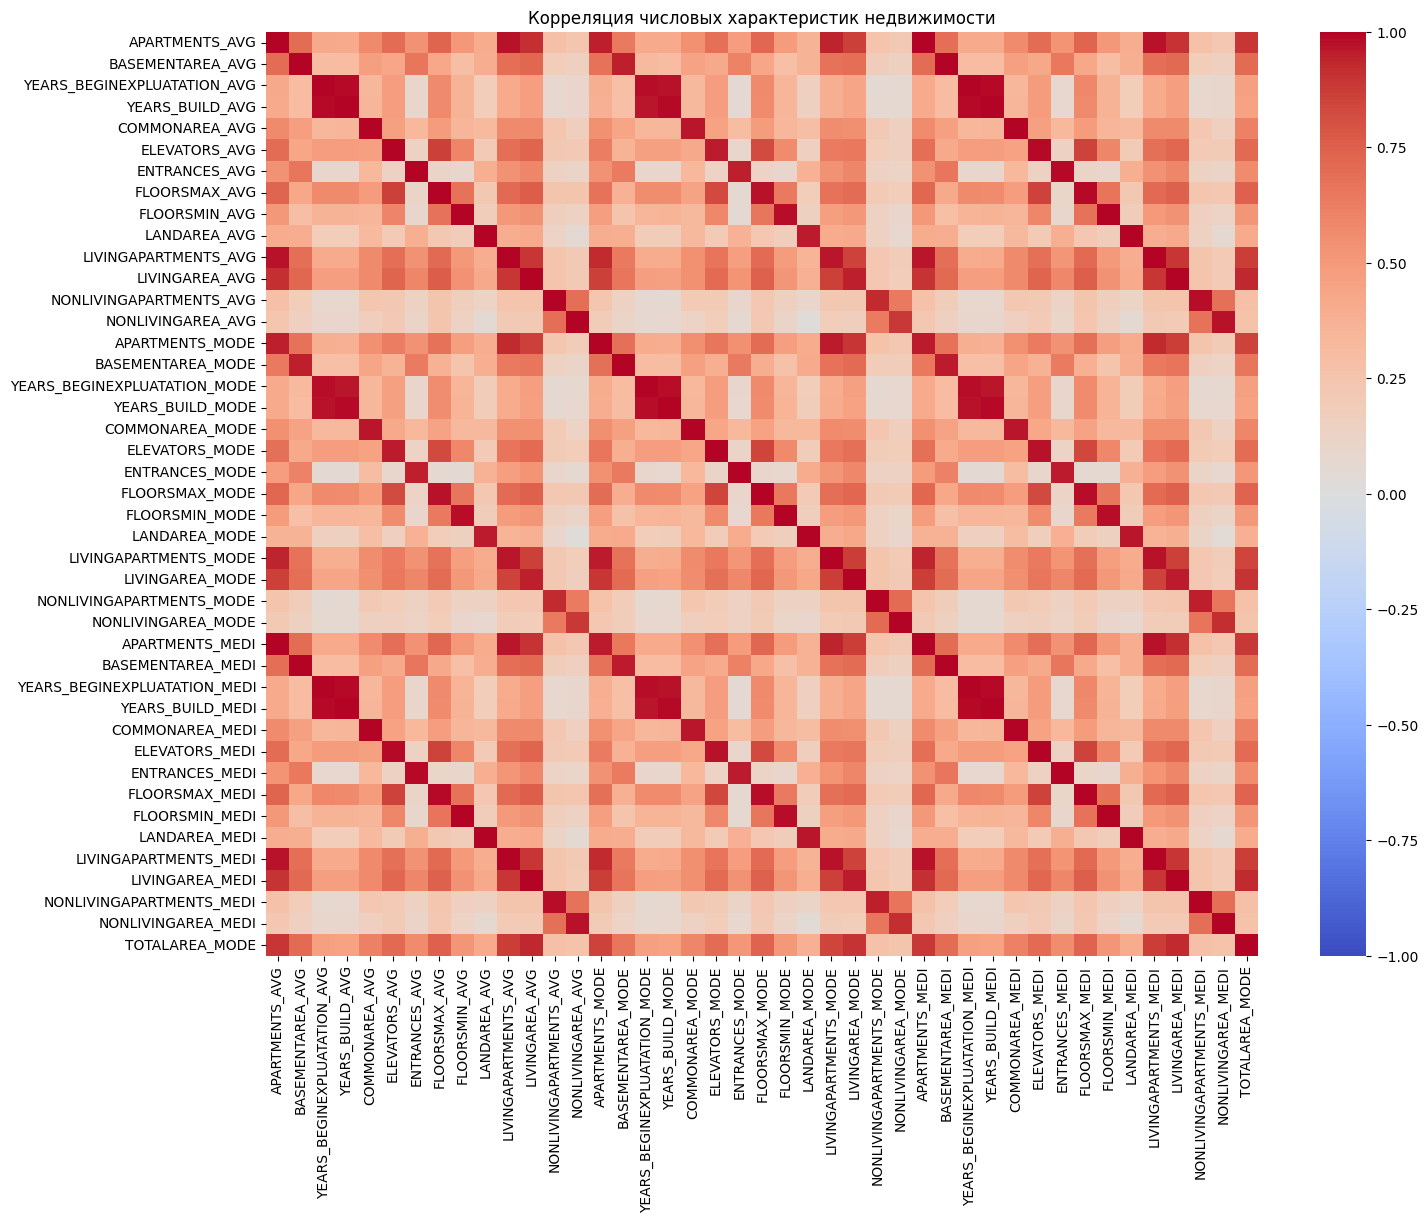

In [29]:
import seaborn as sns
building_numeric = df_train[building].dropna().select_dtypes(include="number")
corr = building_numeric.corr(method="spearman")

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Корреляция числовых характеристик недвижимости")
plt.show()

Матрица корреляций Спирмена показывает высокую положительную корреляцию между различными способами представления одних и тех же характеристик недвижимости (AVG, MODE, MEDI).

Это указывает на частичную избыточность информации в группе признаков. Однако высокая корреляция не означает, что все такие признаки обязательно нужно удалять: CatBoost способен работать с коррелирующими переменными.

## Пол, профессия, образование

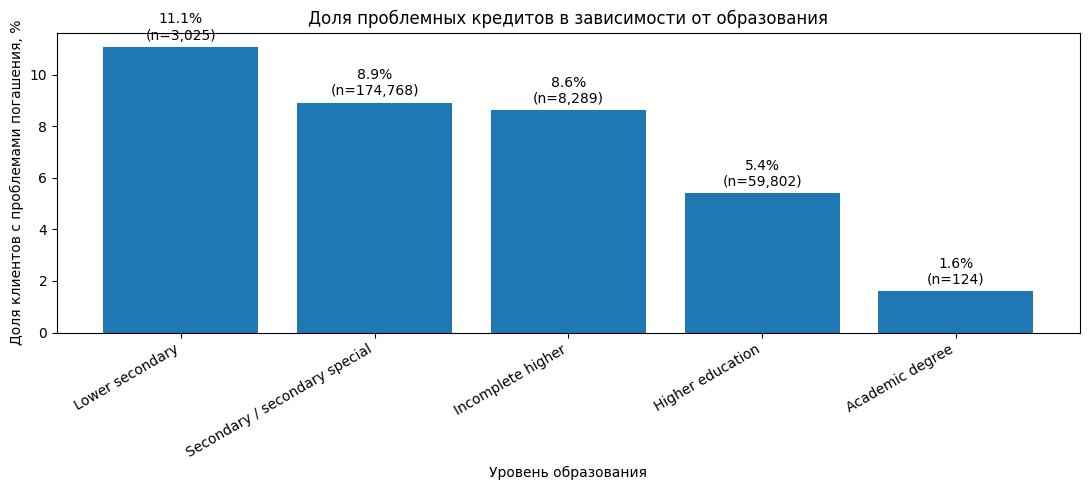

In [30]:
education = df_train.groupby("NAME_EDUCATION_TYPE")["TARGET"].agg(["mean", "count"])
education = education.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(education.index, education["mean"] * 100)

labels = [
    f"{row['mean']:.1%}\n(n={int(row['count']):,})"
    for _, row in education.iterrows()
]

ax.bar_label(bars, labels=labels, padding=3)

ax.set_xlabel("Уровень образования")
ax.set_ylabel("Доля клиентов с проблемами погашения, %")
ax.set_title("Доля проблемных кредитов в зависимости от образования")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Наибольшая доля дефолтов наблюдается среди клиентов с более низким уровнем образования. Например, для категории Lower secondary она составляет около 11,1%, тогда как для клиентов с высшим образованием — около 5,4%.

Это указывает на связь уровня образования с вероятностью дефолта. При этом различия могут быть обусловлены и другими характеристиками клиентов, например доходом и профессией.

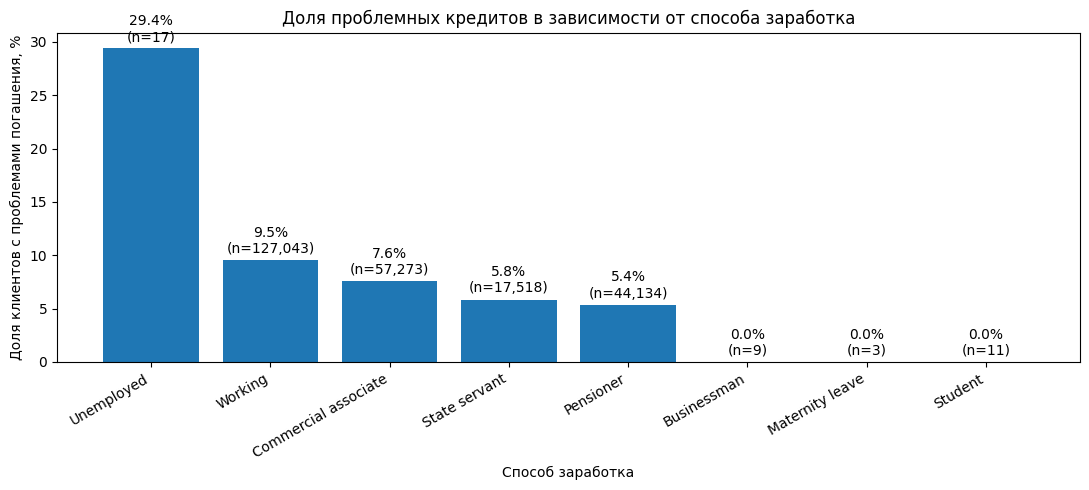

In [31]:
income_type = df_train.groupby("NAME_INCOME_TYPE")["TARGET"].agg(["mean", "count"])
income_type = income_type.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(income_type.index, income_type["mean"] * 100)

labels = [
    f"{row['mean']:.1%}\n(n={int(row['count']):,})"
    for _, row in income_type.iterrows()
]

ax.bar_label(bars, labels=labels, padding=3)

ax.set_xlabel("Способ заработка")
ax.set_ylabel("Доля клиентов с проблемами погашения, %")
ax.set_title("Доля проблемных кредитов в зависимости от способа заработка")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Доля дефолтов различается между категориями источников дохода.

Среди работающих клиентов она составляет около 9,5%, среди коммерческих партнёров — 7,5%, а среди пенсионеров — 5,4%.

Категория Unemployed демонстрирует значительно более высокую долю дефолтов — около 29,4%. Однако в ней всего 17 наблюдений, поэтому делать надёжные выводы по этому значению нельзя.

Таким образом, источник дохода потенциально полезен для прогнозирования дефолта, но при интерпретации необходимо учитывать численность категорий.

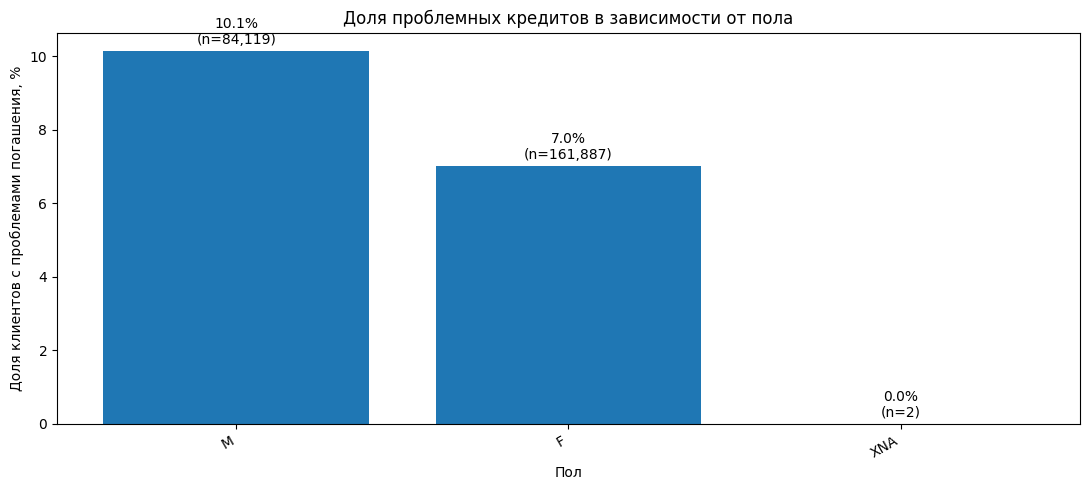

In [32]:
gender = df_train.groupby("CODE_GENDER")["TARGET"].agg(["mean", "count"])
gender = gender.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(gender.index, gender["mean"] * 100)

labels = [
    f"{row['mean']:.1%}\n(n={int(row['count']):,})"
    for _, row in gender.iterrows()
]

ax.bar_label(bars, labels=labels, padding=3)

ax.set_xlabel("Пол")
ax.set_ylabel("Доля клиентов с проблемами погашения, %")
ax.set_title("Доля проблемных кредитов в зависимости от пола")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

В обучающей выборке доля дефолтов среди мужчин составляет около 10,1%, среди женщин — 7,0%.

Это показывает наличие связи между полом и целевой переменной. 

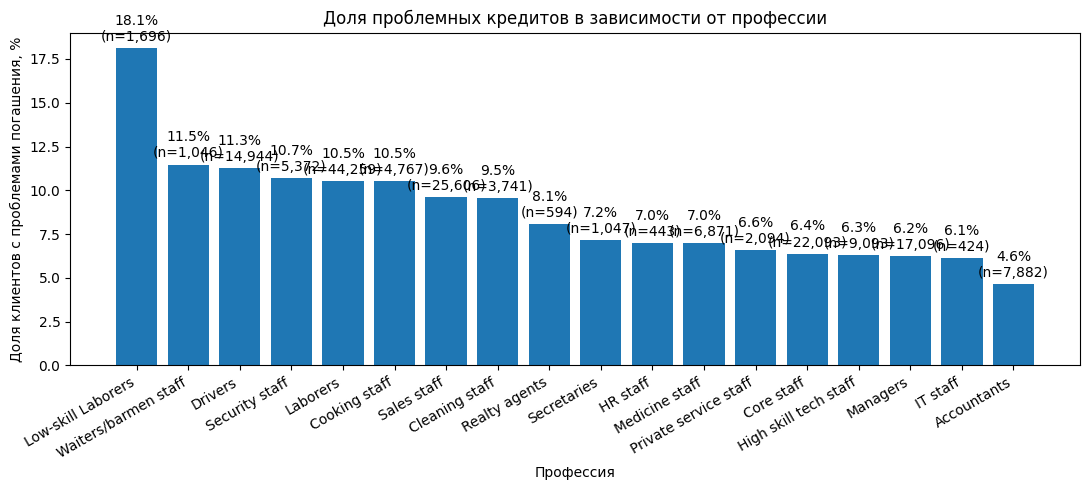

In [33]:
occupation = df_train.groupby("OCCUPATION_TYPE")["TARGET"].agg(["mean", "count"])
occupation = occupation.sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(occupation.index, occupation["mean"] * 100)

labels = [
    f"{row['mean']:.1%}\n(n={int(row['count']):,})"
    for _, row in occupation.iterrows()
]

ax.bar_label(bars, labels=labels, padding=3)

ax.set_xlabel("Профессия")
ax.set_ylabel("Доля клиентов с проблемами погашения, %")
ax.set_title("Доля проблемных кредитов в зависимости от профессии")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Наибольшая доля дефолтов наблюдается среди низкоквалифицированных рабочих, водителей и некоторых категорий работников сферы обслуживания.

Наименьшая доля дефолтов наблюдается, в частности, среди бухгалтеров и высококвалифицированных технических специалистов.

При этом численность профессиональных групп различается, что необходимо учитывать при сравнении результатов.

В дальнейшем можно проверить, помогают ли профессия и связанные с ней признаки улучшить качество прогнозирования.

## Анализ пропусков

В данных много пропусков, но многие из них могут оказаться значимыми. Нужно это проверить.

In [34]:
features = [
    "OCCUPATION_TYPE",
    "OWN_CAR_AGE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_3",
    "APARTMENTS_AVG",
    "YEARS_BUILD_AVG",
]

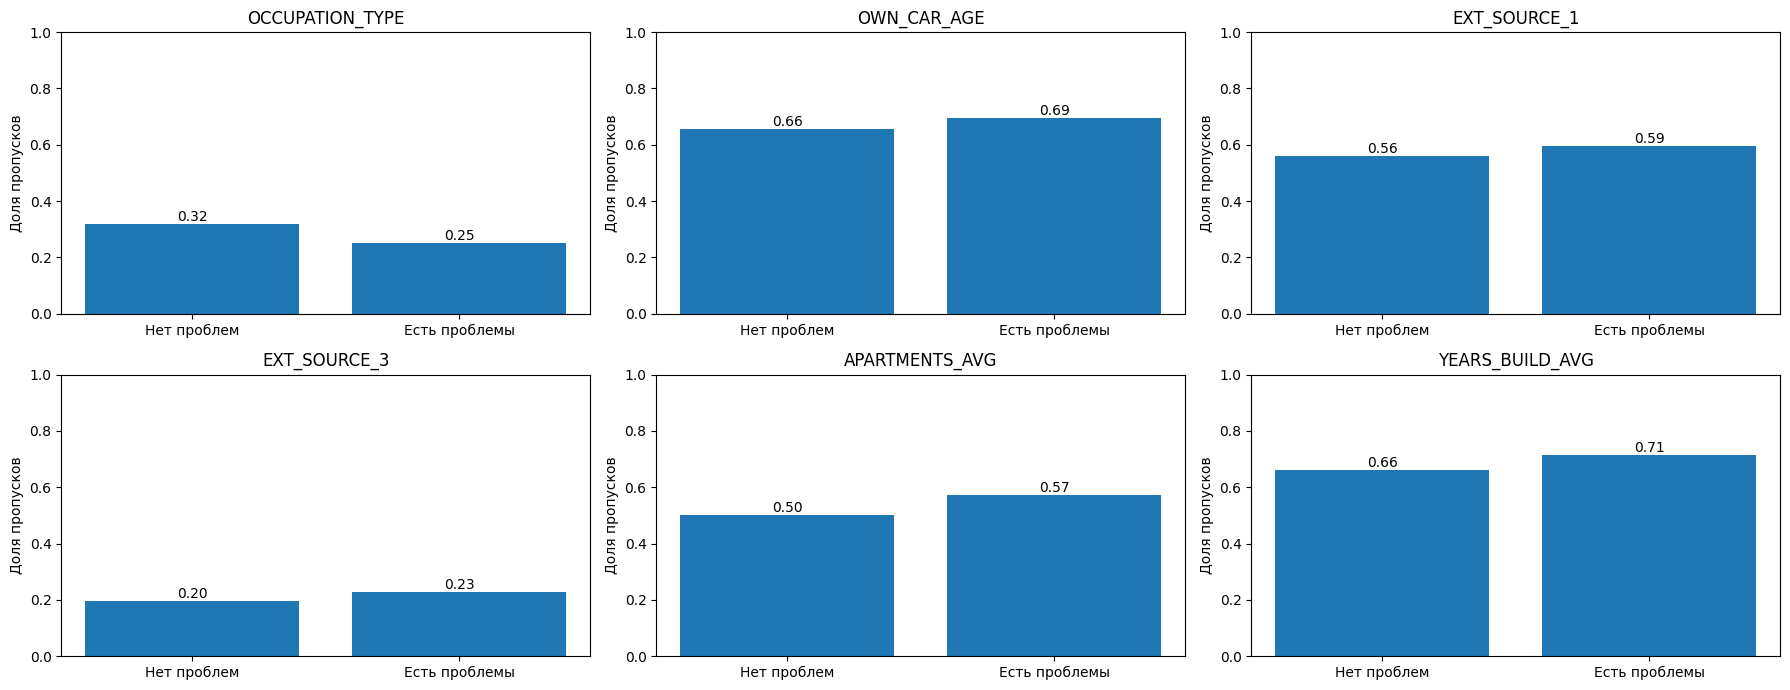

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7))

for feature, ax in zip(features, axes.flatten()):
    no_problems_nans = df_train.loc[df_train["TARGET"] == 0, feature].isna().sum()
    problems_nans = df_train.loc[df_train["TARGET"] == 1, feature].isna().sum()

    bars = ax.bar(
        [0, 1],
        [
            no_problems_nans / df_train[df_train["TARGET"] == 0].shape[0],
            problems_nans / df_train[df_train["TARGET"] == 1].shape[0]
        ]
    )

    ax.bar_label(bars, fmt="%.2f")

    ax.set_xticks(
        [0, 1],
        ["Нет проблем", "Есть проблемы"]
    )

    ax.set_ylabel("Доля пропусков")
    ax.set_title(feature)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

Итак, можно сделать вывод, что отстутствие значений в характеристиках, связанных со зданием, больше, если у заемщика проблемы с погашением кредита. Обратная ситуация с OCCUPATION_TYPE (профессия): чем больше пропусков, тем меньше шанс проблем с погашением.

In [36]:
df_train.loc[df_train["OCCUPATION_TYPE"].isna(), "NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Pensioner               44130
Working                 19922
Commercial associate     9869
State servant            2997
Unemployed                 17
Businessman                 2
Student                     2
Maternity leave             1
Name: count, dtype: int64

Видно, что большая часть с пропусками в OCCUPATION_TYPE - пенсионеры, поэтому и доля дефолтов там меньше.

Так что пропуски в этой колонке не сами по себе важны, а просто частично дублируют информацию из NAME_INCOME_TYPE.

In [37]:
df_train["BUILDING_MISSING_COUNT"] = df_train[building].isna().sum(axis=1)

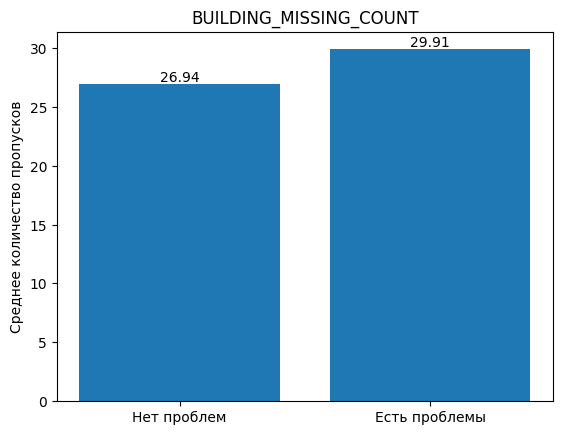

In [38]:
no_problems_nans = df_train.loc[df_train["TARGET"] == 0, "BUILDING_MISSING_COUNT"].mean()
problems_nans = df_train.loc[df_train["TARGET"] == 1, "BUILDING_MISSING_COUNT"].mean()
bars = plt.bar(
    [0, 1],
    [
        no_problems_nans,
        problems_nans
    ]
)

plt.bar_label(bars, fmt="%.2f")

plt.xticks(
    [0, 1],
    ["Нет проблем", "Есть проблемы"]
)

plt.ylabel("Среднее количество пропусков")
plt.title("BUILDING_MISSING_COUNT")
plt.show()

Доли пропущенных значений отличаются между клиентами с дефолтом и без него.

Для признаков, описывающих недвижимость, а также некоторых внешних оценок пропуски несколько чаще встречаются среди клиентов с дефолтом.

В то же время пропуски в OCCUPATION_TYPE чаще наблюдаются среди клиентов без дефолта. Дополнительная проверка показала, что значительная часть таких наблюдений относится к пенсионерам.

Это позволяет предположить, что пропуски могут быть связаны с другими характеристиками заёмщиков и потенциально содержать полезную для модели информацию.

# Выводы

В ходе разведочного анализа были исследованы характеристики заёмщиков, распределение целевой переменной, связи отдельных признаков с дефолтом, корреляции и структура пропущенных значений.

**Основные результаты исследования:**

* **Дисбаланс классов.** Доля клиентов с дефолтом составляет около 8,1%. Для оценки качества модели будет использоваться ROC-AUC, дополнительно — Average Precision.

* **Доход и сумма кредита.** У клиентов без дефолта медианный доход выше, однако размер эффекта невелик. Медианная сумма кредита также оказалась несколько выше среди клиентов без дефолта, что не соответствует первоначальной гипотезе.

* **Возраст.** Более молодые заёмщики чаще допускают дефолт. Связь возраста с целевой переменной заметнее, чем связь дохода.

* **Проживание не по месту регистрации.** Среди клиентов с дефолтом чаще встречаются заёмщики, проживающие не по месту регистрации. Однако сила связи невелика.

* **Внешние оценки.** Признаки EXT_SOURCE_1, EXT_SOURCE_2 и EXT_SOURCE_3 демонстрируют заметные различия между группами и представляют интерес для дальнейшего моделирования.

* **Категориальные характеристики.** Обнаружены различия в частоте дефолтов между категориями образования, профессии, пола и источника дохода. Эти зависимости требуют осторожной интерпретации и не доказывают причинно-следственных связей.

* **Характеристики недвижимости.** Многие признаки сильно коррелируют между собой. Кроме того, у клиентов с дефолтом в среднем наблюдается больше пропусков в этой группе.

* **Пропущенные значения.** Отсутствие информации может быть связано с характеристиками клиентов. Например, значительная часть пропусков в OCCUPATION_TYPE приходится на пенсионеров.

**Дальнейшие шаги**

На основании EDA в следующем этапе планируется:

* Создать дополнительные признаки на основе возраста, дохода и кредитной нагрузки.

* Сформировать агрегированные признаки из кредитной истории, предыдущих заявок и платежей.

* Создать признаки, отражающие структуру пропусков.

* Проверить корректность объединения таблиц и возможные временные утечки.

* Оценить полезность новых признаков с помощью кросс-валидации CatBoost.

Выявленные в EDA закономерности характеризуют отдельные признаки, но не гарантируют их полезности для итоговой модели. Окончательные выводы об их прогностической ценности будут сделаны по результатам моделирования.